# Concept lattice: original context vs. present/absent swapped

**Question:** if every attribute is flipped (present ↔ absent), is the concept lattice the same shape?

- *Original*: `config.CONTEXT` — 8 objects (g0–g7), 6 attributes (m0–m5), each object has 3 of 6.
- *Swapped*: every 1 becomes 0 and every 0 becomes 1. Each object still has 3 of 6 attributes.

Nodes are concepts. Labels use reduced labelling: an object is written at the lowest concept that contains it, an attribute at the highest concept that has it. A line means "directly above" (larger set of objects, fewer shared attributes).

In [1]:
import sys
from pathlib import Path

import pandas as pd

# config.py and lattice.py live in demo/, next to analysis/
sys.path.insert(0, str(Path.cwd().parent / "demo"))
from config import CONTEXT, ATTRIBUTES
from lattice import mk_formal_context

SWAPPED = {obj: [1 - value for value in row] for obj, row in CONTEXT.items()}
columns = [f"m{j} {ATTRIBUTES[f'm{j}']['feature']}" for j in range(6)]

## The two formal contexts

In [2]:
pd.DataFrame(CONTEXT, index=columns).T

,m0 colour,m1 stripes,m2 outline,m3 hole,m4 slot,m5 circle
g0,1,1,1,0,0,0
g1,1,0,1,0,1,0
g2,1,1,0,1,0,0
g3,1,0,0,1,0,1
g4,0,0,0,1,1,1
g5,0,1,0,1,0,1
g6,0,0,1,0,1,1
g7,0,1,1,0,1,0


In [3]:
pd.DataFrame(SWAPPED, index=columns).T

,m0 colour,m1 stripes,m2 outline,m3 hole,m4 slot,m5 circle
g0,0,0,0,1,1,1
g1,0,1,0,1,0,1
g2,0,0,1,0,1,1
g3,0,1,1,0,1,0
g4,1,1,1,0,0,0
g5,1,0,1,0,1,0
g6,1,1,0,1,0,0
g7,1,0,0,1,0,1


## Lattices

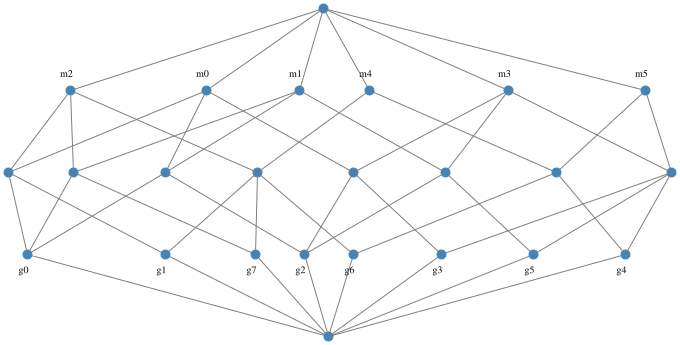

In [4]:
def show(context):
    """The lattice as a graphviz picture, shown in the notebook (not saved)."""
    dot = mk_formal_context(context).lattice.graphviz(
        make_object_label=lambda objs: ", ".join(objs),
        make_property_label=lambda props: ", ".join(props))
    dot.node_attr.update(width="0.12", fillcolor="steelblue", color="steelblue")
    dot.edge_attr.update(color="gray50", fontsize="10")
    dot.graph_attr.update(nodesep="0.3", splines="line")
    return dot

show(CONTEXT)

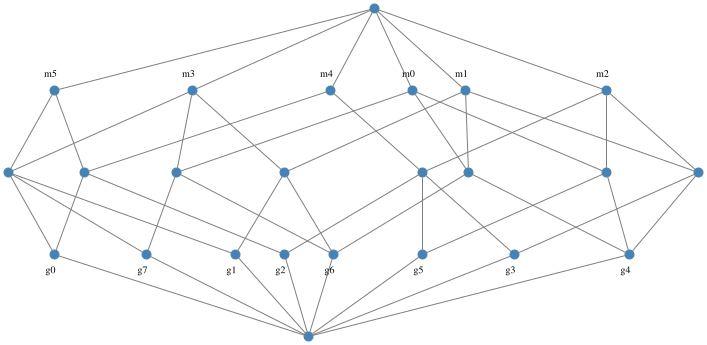

In [5]:
show(SWAPPED)

## Are they the same shape?

In [6]:
for name, context in (("original", CONTEXT), ("swapped", SWAPPED)):
    lattice = mk_formal_context(context).lattice
    edges = sum(len(c.upper_neighbors) for c in lattice)
    levels = pd.Series([len(c.intent) for c in lattice]).value_counts().sort_index()
    print(f"{name:9s} {len(lattice)} concepts, {edges} lines; "
          f"concepts per number of shared attributes: { {int(k): int(v) for k, v in levels.items()} }")

original  24 concepts, 48 lines; concepts per number of shared attributes: {0: 1, 1: 6, 2: 8, 3: 8, 6: 1}
swapped   24 concepts, 48 lines; concepts per number of shared attributes: {0: 1, 1: 6, 2: 8, 3: 8, 6: 1}


In [7]:
# Each swapped row compared with the original rows: does it equal one of them?
rows = {tuple(row): obj for obj, row in CONTEXT.items()}
pd.DataFrame({
    "swapped row": ["".join(map(str, SWAPPED[obj])) for obj in CONTEXT],
    "same as original row of": [rows.get(tuple(SWAPPED[obj]), "none") for obj in CONTEXT],
}, index=list(CONTEXT))

,swapped row,same as original row of
g0,000111,g4
g1,010101,g5
g2,001011,g6
g3,011010,g7
g4,111000,g0
g5,101010,g1
g6,110100,g2
g7,100101,g3
